In [1]:
import time
import sys
import os

# Add the parent directory to sys.path
notebook_path = os.getcwd()  # Get the current working directory where the notebook is located
parent_directory = os.path.dirname(notebook_path)  # Move to the parent directory
sys.path.append(parent_directory)

# Now you can import config
from config import *
#from Minimal_Model_2D import *
import Minimal_Model_2D as mm2d
import time

np.set_printoptions(threshold=sys.maxsize)

In [3]:
NSM = 60            # number of sm x lattice points
M = 60              # should be atleast thrice confinement length
AX = 5              # lattice spacing in nm
AY = 5              # lattice spacing in nm
DELTA = 0.165       # in meV
MEFF_SC = 0.005     # proximitized Ge
MEFF_SM = 0.005     # Ge
NSC = 800
NTOT = 2*NSC + NSM
PHI = 0.5*np.pi 
ALPHAT = 400        # meV-nm^3 # 20 is within perturbative regime for widths atleast up to 100 nm
K_NUM = 8           # No of eigenvalues needed to be found 
#W_MIN = 50

LY = 100           # Width in nm
OMEGA = 2*4*hbm/LY**2/MEFF_SC

MY= 5 

print('lengths=', M*AY, LY)
OMEGA = 2*4*hbm/LY**2/MEFF_SC

print('subband energies=', OMEGA/2, 3*OMEGA/2)

print('4t=', 4*hbm/AX**2/MEFF_SM)

MU_SC =   OMEGA/2 +OMEGA/10  # in between two subbands - such that we get two abs prferably 
MU_SM =   OMEGA/2 +OMEGA/10  # in between two subbands - such that we get two abs prferably

print('mu = ', MU_SM)


UNCORR_VAR = 0  ### uncorrelated variance of disorder
LMBDA = 0
SEED = 58  ## seed for the disorder

ModCT = mm2d.twoD_Minimal_Model(NTOT, NSM, NSC, M, AX, AY, OMEGA, ALPHAT, DELTA, MEFF_SC, MEFF_SM, MU_SC, MU_SM)

lengths= 300 100
subband energies= 3.050591261472007 9.15177378441602
4t= 1220.2365045888027
mu =  3.6607095137664083


In [5]:
XCT = np.linspace((NSC-10)*AX, (NSC+NSM+10)*AX, 21)
YCT = M/2*AY

Ep = np.empty((XCT.shape[0],K_NUM))

for i in range(XCT.shape[0]):

    H = ModCT.H_sys(PHI, 'cu', XCT[i], YCT)

    E = eigsh(H, k=K_NUM, sigma=0, return_eigenvectors=False )

    Es = np.sort(E)/DELTA

    Ep[i,:] = Es

    print(Ep[i,:])

np.save('cubic_E_vs_xct_V1.npy', Ep)

[-1.03200401 -1.03199612 -0.55156419 -0.55144661  0.55144661  0.55156419
  1.03199612  1.03200401]
[-1.03200315 -1.03199526 -0.55155041 -0.55143284  0.55143284  0.55155041
  1.03199526  1.03200315]
[-1.03200145 -1.03199356 -0.55152678 -0.55140923  0.55140923  0.55152678
  1.03199356  1.03200145]
[-1.03199679 -1.0319889  -0.55148159 -0.55136406  0.55136406  0.55148159
  1.0319889   1.03199679]
[-1.03198625 -1.03197835 -0.55140191 -0.55128441  0.55128441  0.55140191
  1.03197835  1.03198625]
[-1.03196973 -1.03196182 -0.55129016 -0.55117267  0.55117267  0.55129016
  1.03196182  1.03196973]
[-1.03194995 -1.03194203 -0.55116257 -0.55104509  0.55104509  0.55116257
  1.03194203  1.03194995]
[-1.0319302  -1.03192229 -0.55103818 -0.5509207   0.5509207   0.55103818
  1.03192229  1.0319302 ]
[-1.03191345 -1.03190552 -0.55093393 -0.55081645  0.55081645  0.55093393
  1.03190552  1.03191345]
[-1.03190199 -1.03189406 -0.55086316 -0.55074568  0.55074568  0.55086316
  1.03189406  1.03190199]
[-1.031897

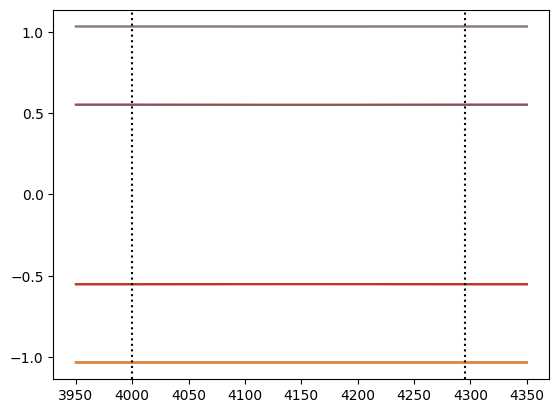

In [6]:
plt.plot(XCT, Ep[:, :])
plt.axvline(x=NSC*AX, color='black', linestyle='dotted')
plt.axvline(x=(NSC+NSM-1)*AX, color='black', linestyle='dotted')

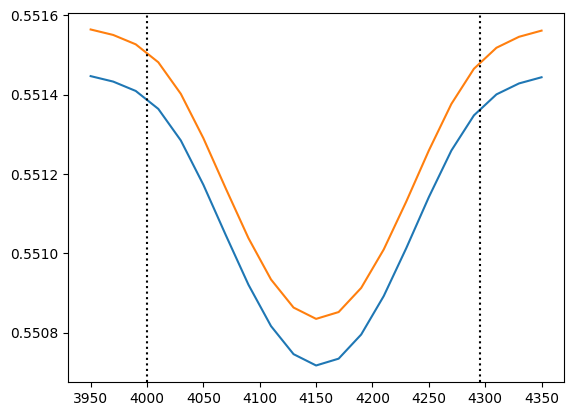

In [9]:
plt.plot(XCT, Ep[:, K_NUM//2:K_NUM//2+2])
plt.axvline(x=NSC*AX, color='black', linestyle='dotted')
plt.axvline(x=(NSC+NSM-1)*AX, color='black', linestyle='dotted')

(0.0, 0.00014110027318041672)

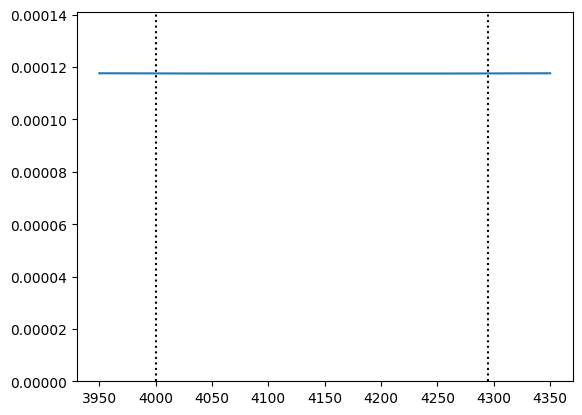

In [12]:
plt.plot(XCT, Ep[:, K_NUM//2+1]-Ep[:, K_NUM//2])
plt.axvline(x=NSC*AX, color='black', linestyle='dotted')
plt.axvline(x=(NSC+NSM-1)*AX, color='black', linestyle='dotted')
plt.ylim(ymin=0,ymax = 1.2*np.max(Ep[:, K_NUM//2+1]-Ep[:, K_NUM//2]))

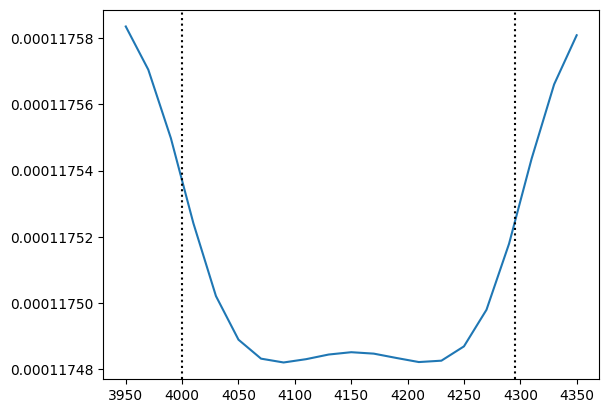

In [13]:
plt.plot(XCT, Ep[:, K_NUM//2+1]-Ep[:, K_NUM//2])
plt.axvline(x=NSC*AX, color='black', linestyle='dotted')
plt.axvline(x=(NSC+NSM-1)*AX, color='black', linestyle='dotted')
#plt.ylim(ymin=0,ymax = 1.2*np.max(Ep[:, K_NUM//2+1]-Ep[:, K_NUM//2]))